# 03c Tuning room: the own-face patch on a held-out room (issue #20)

**Why this notebook exists.** The Phase 0.5 gate fails on room B (`03a`, `03b`, `05b`). Room B is the gate's own slice, so 03a's method must not be tuned there (owner's decision, #20). It is tuned on **held-out rooms of the CRAS lab**, and room B is re-run once afterwards. There are two tuning rooms, one notebook each with the same code: `03c_tuning_room.ipynb` (the south part of the west hall) and `03c_tuning_room_a.ipynb` (room A). **This notebook is room A, the room south of room B.** Phase 1 (baseline, proxy, diagnosis, known answers) found that the label-free verdicts lose points that are not on the element's face at all; phase 2 implements the one change the owner chose, **the own-face patch**, and tunes its two judgement calls on the two held-out rooms only. The thresholds are fixed and untouched: `TOL` 15 mm (USIBD LOA30) and `MIN_FRAC_OK` 0.95 (LOA30's confidence level).

**The room.** Room A (`03c_tuning_slice_room_a.json`: box x 0.38 to 8.30 m, y -4.32 to 2.92 m, 28 elements, 3.0 M scan points). It shares room B's south wall `Drywall:961571` (hand-check element 6), which is excluded from scoring and tuning, and 11 other elements that room B's list also holds (the building-wide floor slab and east wall, two ceiling coverings, two of room B's west walls, five windows on the boundary strip). All 12 stay in the room (their points must be assigned to something) and none is scored; 16 elements are.

**How 03a's logic runs on it.** 03a is hard-wired to room B and is the gate notebook. This notebook carries a **copy of 03a's logic**, as 03b does, plus the patch; `SLICE_JSON` selects the slice (this room by default; `01_cras_slice.json` runs room B, where the copy must reproduce 03a's CSVs, asserted in the report cell and by `tests/test_notebook_03c.py`). A wall with no scan point in its band is skipped (one guard that 03a does not need on room B).

**What it does.** (1) 03a's verdict table on this room, without and with oracle labels (the patch off). (2) A **proxy for the hand check**: per element a truth that does not use the verdict rule. (3) A **diagnosis** of why the label-free shares fall below 95 %. (4) The label-free **frame** against the oracle-point frame. (5) **The own-face patch** per element, and the two judgement calls (the edge allowance, the element classes) against the proxy and the verdicts of this room. (6) **Known answers** by perturbation, 03b's way, with and without the patch. **Elements that room B's element list also holds are kept in the room (their points must be assigned to something) but are never scored or tuned on**; `scoring_exclusions` in the slice JSON lists them.

Terms are defined in [CONTEXT.md](../CONTEXT.md). All randomness is seeded. Nothing is written outside `outputs/` (gitignored).

## 1. Parameters and load

03a's parameters, unchanged (with their justification comments, as in 03b), then the contract from the slice JSON, the room's elements tessellated with `only_guids`, and the scan cache transformed in chunks and cropped to the box padded by `PAD` (03a section 1). The slice JSON has 01's schema and 01's recorded transform (the lab's, reused unchanged).

In [1]:
import csv, dataclasses, json, os, resource, time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
from IPython.display import Image, display

from scan_vs_bim.compare import aligned_faces, over_own_face
from scan_vs_bim.load import load_ifc_elements, merge_meshes

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
reg = o3d.pipelines.registration

# Parameters: 03a's, unchanged, with 03a's justification comments (03a's cross-references to its own sections kept as '03a's section N'). Lengths in metres.
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
# The slice is chosen by the SLICE_JSON environment variable (a file name in notebooks/): this notebook's tuning room by default, or "01_cras_slice.json" (room B)
# to check that this notebook's copy of 03a's logic gives room B's 03a verdicts. Outputs go to a different folder for each, never to outputs/03a.
SLICE = Path(os.environ.get("SLICE_JSON", "03c_tuning_slice_room_a.json"))
ROOM_B_RUN = SLICE.name == "01_cras_slice.json"
OUT = Path("../outputs") / {"03c_tuning_slice.json": "03c", "03c_tuning_slice_room_a.json": "03c_room_a", "01_cras_slice.json": "03c_room_b_check"}[SLICE.name]  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")

TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (95 %); quoted in 03a's section 3
BAND = 0.10  # (judgement call) scan points further than this from every element surface are ignored; the same as 00
PAD = BAND  # (judgement call) the room box is padded by this much when cropping, see 03a's section 3 for why
MIN_POINTS = 2000  # (judgement call) 1 cm voxels give one point per cm2, so 2000 points is about 0.2 m2 (a 45 cm square) of scanned surface
MIN_FRAC_OK = 0.95  # LOA30 is "specified at the 95 % confidence level": 15 mm is at 2 sigma, so 95 % of an element's points must lie within it
                    # (00's toy used 0.8; 03a's section 4 shows that value too)
MIN_FRAC_CLUSTER = 0.8  # (judgement call, not from the standard) shifted: share of points within TOL of the element's median. Clutter and element edges
                        # leave a real offset plane only 78 to 94 % near its median on this room, so 95 % is too strict here; 0.8 still rejects a 55/45 bimodal wall
SIDE_NEAR, SIDE_FAR, SIDE_STEP = 0.03, 0.20, 0.02  # (judgement call) wall side test: look this far from a wall point along the thickness axis: beyond the point's own surface noise,
                                                    # past a 10 cm drywall's other face, short of most furniture. Steps are one occupancy voxel
OCC_VOXEL = 0.02  # (judgement call) occupancy grid voxel for the side test: 2 cm, about 35 MB as a dense bool array over the crop
VOTE_BIN = 0.005  # plane vote: 5 mm bins along the thickness axis; the window is TOL each side (VOTE_HALF bins)
VOTE_HALF = round(TOL / VOTE_BIN)
VOTE_SHARE = 0.5  # (judgement call) a plane takes the side that more than half of all its points show by themselves; 03a's section 3 gives the reason
JUNCTION = 0.10  # (judgement call) a wall point within this distance of any other element's surface (ceiling, floor, window, door, another wall) is left out of the wall's verdict:
                 # it is at a junction, and could belong to either element. 03a's section 3 gives the reason and the sensitivity (0, 5, 10, 15 cm)
MIN_AREA_IN_BOX = 0.10  # (judgement call) below this share of an element's surface inside the room box, the in-box part is too small to stand for the element
PROBE = 0.05  # (judgement call) a wall face is room-facing if the point this far outside it, along its normal, is within the room box's extent

N_MODEL_SAMPLES, MODEL_CLIP = 3_000_000, 0.3  # points sampled on the 35 elements; kept within this margin of the box
ICP_DIST = 0.10  # plain point-to-plane ICP
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust pass: Tukey loss gives residuals beyond 2 cm no weight
SANITY_ROT_DEG, SANITY_TRANS_M = 0.5, 0.05  # 03a's bounds on the ICP correction

# 03c: parameters of the known answers and the proxy (decisions fixed before the run, see the text)
EDGE = 0.10  # (judgement call) 03a's clean-plane definition: wall points closer than this to another element are at a junction, not on the plain wall
CLEAN_Z = (0.15, 2.70)  # (judgement call) 03a's clean-plane definition: height range of a wall's plain area, away from the floor and ceiling junctions
MOVE_M = (0.01, 0.03, 0.10)  # the sizes of the injected wall moves (m), as in 03b; each move is its own run
MEDIAN_ERR = 0.001  # a move is "read" if the wall's median offset changes by the injected change to within 1 mm (03b's)
CLUTTER_FRONT = (0.03, 1.0)  # (judgement call, diagnosis) clutter "in front of" a wall: clutter-class points this far from it along its normal (03b's OCC_NEAR, OCC_FAR)

# Issue #20, the own-face patch (scan_vs_bim.compare.over_own_face): a counted point must lie over the element's own face; points past its edges are left out. Judgement calls, tuned on the
# west hall and room A only (section 7), never on room B.
PATCH_MARGIN = 0.01  # (judgement call) edge allowance in m: a point this close to the face's edge, measured in the face's plane, still counts
PATCH_CLASSES = ("IfcWallStandardCase", "IfcSlab", "IfcCovering")  # (judgement call) the element classes the patch applies to: those with one or two broad faces; a window's or door's faces are recessed and cut up
PATCH_ONE_SIDED = True  # (judgement call) a wall is patched only if exactly one of its faces is room-facing; a partition (two room-facing faces) is left as it was: which of its faces a point is over
                        # is the side test's open question, and a moved wall whose far face lands in the box reads as a partition (section 8)

T0 = time.time()
def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)

In [2]:
slice_ = json.loads(SLICE.read_text())
ROOM, FRAME = slice_["room"], slice_["frame"]
EXCLUDED_IDS = {e["global_id"] for e in slice_.get("scoring_exclusions", [])}  # kept in the room, never scored or tuned on (room B's own elements)
T_REC = np.array(FRAME["scan_to_model_4x4"])  # scan frame -> model frame, as recorded by 01
BOX = ROOM["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
GUIDS = ROOM["element_global_ids"]
META = {e["global_id"]: e for e in ROOM["elements"]}
assert slice_["scanner_positions"]["recovered"] is False  # so missing / not visible are not reachable (03a: no scanner positions on CRAS)

t = time.time()
by_id = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=GUIDS)}  # tessellation first: it has the higher memory peak
assert set(by_id) == set(GUIDS), f"not all {len(GUIDS)} room elements were found in the IFC"
elements = [by_id[g] for g in GUIDS]
assert all(e.ifc_class in ELEMENT_CLASSES and e.ifc_class == META[e.global_id]["ifc_class"] for e in elements)
print(f"{len(elements)} elements tessellated in {time.time() - t:.0f} s, {sum(len(e.faces) for e in elements):,} triangles")

t = time.time()
cache = np.load(CACHE)
xyz, cls_all = cache["xyz"], cache["cls"]  # scan frame; the cache's rgb is not read
n_total = len(xyz)
parts, class_parts = [], []
for i in range(0, n_total, 4_000_000):
    p = apply(T_REC, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    parts.append(p[keep])
    class_parts.append(cls_all[i:i + 4_000_000][keep])
del xyz, cls_all, cache
P_REC = np.concatenate(parts)  # room crop, model frame (recorded transform), float32
SCAN_CLASS = np.concatenate(class_parts)
del parts, class_parts
in_box = ((P_REC >= box_lo) & (P_REC <= box_hi)).all(1)
assert in_box.sum() == ROOM["scan_points_in_box"], "box crop differs from 01's count"
element_ids = [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES]
is_element_class = np.isin(SCAN_CLASS, element_ids)
is_clutter_class = ~is_element_class & (SCAN_CLASS != CLASS_NAMES.index("unassigned"))  # 03b: a scan class that is neither an element's nor 'unassigned'
print(f"cache {n_total:,} points -> {len(P_REC):,} in the box padded by {PAD * 100:.0f} cm ({time.time() - t:.0f} s); "
      f"element scan classes {is_element_class.sum():,}, clutter classes {is_clutter_class.sum():,}, unassigned {(SCAN_CLASS == 0).sum():,}")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

28 elements tessellated in 36 s, 194,278 triangles


cache 20,404,814 points -> 3,267,823 in the box padded by 10 cm (3 s); element scan classes 2,160,284, clutter classes 664,806, unassigned 442,733
peak RSS so far: 1.64 GB


## 2. 03a's logic (copied), the frame, and the baseline run

The functions are 03a's (`icp_target`, `refine`, `judge`, `room_facing`, `place_wall_points` with the wall side test, `measure` with the junction margin, `assign`, `verdict_rows`), as copied into 03b, plus the one guard named above. The own-face patch (`own_face_triangles`, `patched_view`: section 7) is defined in the cell after. Then 03a's section 2 and 3 for this room: ICP refinement from the recorded transform on **all** crop points (no labels), its sanity check, the assignment of every point to its nearest element, and the verdicts. The refined frame is used for everything below (a frozen frame, as in 03b).

In [3]:
# ---- 03a's logic, copied and wrapped in functions (same parameters and rules; the baseline-count assert checks it) ------------------------------------------------------------------------------------------
def delta(T_a, T_b, centroid):
    # How far apart two scan -> model transforms are: rotation (deg) between them, and the displacement (m) of the room centroid.
    residual = T_a @ np.linalg.inv(T_b)
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


def icp_target(els):
    # Points sampled on the elements (all faces), kept within MODEL_CLIP of the box; and the centroid of those within the scan crop.
    o3d.utility.random.seed(SEED)
    sampled = merge_meshes(els).sample_points_uniformly(N_MODEL_SAMPLES, use_triangle_normal=True)
    q = np.asarray(sampled.points)
    target = sampled.select_by_index(np.flatnonzero(((q >= box_lo - MODEL_CLIP) & (q <= box_hi + MODEL_CLIP)).all(1)))
    q = np.asarray(target.points)
    return target, q[((q >= crop_lo) & (q <= crop_hi)).all(1)].mean(0)


def refine(points, target):
    # ICP from the recorded transform: the scan is already in the model frame under T_REC, so ICP starts at the identity and its result
    # is the correction in the model frame: T_refined = correction @ T_REC.
    src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points.astype(np.float64)))
    est = reg.TransformationEstimationPointToPlane
    plain = reg.registration_icp(src, target, ICP_DIST, np.eye(4), est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50))
    robust = reg.registration_icp(src, target, ICP_FINE_DIST, plain.transformation, est(reg.TukeyLoss(TUKEY_K)),
                                  reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
    return plain, robust


def mesh_of(e, flip=False):
    f = e.faces[:, [0, 2, 1]] if flip else e.faces
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(f))
    m.compute_triangle_normals()
    return m


def judge(s, area_frac=1.0, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK, min_cluster=MIN_FRAC_CLUSTER):
    # One element's verdict from its signed offsets s (metres, within BAND) and the share of its surface inside the box.
    n = len(s)
    median = float(np.median(s)) if n else float("nan")
    spread = 1.4826 * float(np.median(np.abs(s - median))) if n else float("nan")  # robust sigma, informational only
    share = float(np.mean(np.abs(s) <= TOL)) if n else 0.0
    one_cluster = float(np.mean(np.abs(s - median) <= TOL)) if n else 0.0  # share of points within TOL of the median
    if area_frac < MIN_AREA_IN_BOX:
        verdict, reason = "not confirmed", "mostly outside the room box"
    elif n < min_points:
        verdict, reason = "not confirmed", "too few points"
    elif share >= min_frac:
        verdict, reason = "OK", ""
    elif abs(median) > TOL and one_cluster >= min_cluster:
        verdict, reason = "shifted", ""
    else:
        verdict, reason = "not confirmed", "inconsistent offsets"
    return dict(verdict=verdict, reason=reason, point_count=n, median_m=median, spread_m=spread, share_within_tol=share,
                cluster_share=one_cluster)


def room_facing(e, lo, hi):
    # Boolean per triangle of a wall: vertical faces whose outward normal points into the box [lo, hi] (plan view); the box is taken along the
    # normal only, because a wall runs on beyond the box and its triangles there still face the same way.
    n = np.asarray(mesh_of(e).triangle_normals)
    probe = e.vertices[e.faces].mean(1) + PROBE * n
    a, b = n[:, :2] * lo[:2], n[:, :2] * hi[:2]
    s = (probe[:, :2] * n[:, :2]).sum(1)
    return (np.abs(n[:, 2]) < 0.5) & (s >= np.minimum(a, b).sum(1)) & (s <= np.maximum(a, b).sum(1))


def closest_signed(scene, normals, first, pts):
    # Nearest triangle of the scene to each point: its geometry id, the distance, and the offset along that triangle's normal.
    geom, dist, signed = np.empty(len(pts), np.int32), np.empty(len(pts), np.float32), np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 500_000):
        p = np.ascontiguousarray(pts[i:i + 500_000], dtype=np.float32)
        r = scene.compute_closest_points(o3d.core.Tensor(p))
        g, prim, foot = r["geometry_ids"].numpy(), r["primitive_ids"].numpy(), r["points"].numpy()
        geom[i:i + 500_000] = g
        dist[i:i + 500_000] = np.linalg.norm(p - foot, axis=1)
        signed[i:i + 500_000] = np.einsum("ij,ij->i", p - foot, normals[first[g] + prim])
    return geom, dist, signed


# How place_wall_points decided a point's side
HOW_OWN, HOW_PLANE, HOW_AMBIGUOUS = 1, 2, 3  # its own free space; its plane's side; neither (the nearest room-facing face decides)


def occupancy(pts):
    # Dense boolean grid over the points' bounding box: True where a voxel of OCC_VOXEL holds at least one scan point.
    lo = pts.min(0).astype(np.float64)
    grid = np.zeros(np.ceil((pts.max(0) - lo) / OCC_VOXEL).astype(int) + 1, bool)
    j = np.floor((pts - lo) / OCC_VOXEL).astype(int)
    grid[j[:, 0], j[:, 1], j[:, 2]] = True
    return lo, grid


def occupied_along(occ, p, axis, sign):
    # Per point: is any voxel occupied from SIDE_NEAR to SIDE_FAR away along sign * axis? Outside the grid counts as free.
    lo, grid = occ
    hit = np.zeros(len(p), bool)
    for d in np.arange(SIDE_NEAR, SIDE_FAR + 1e-9, SIDE_STEP):
        q = p.astype(np.float64)
        q[:, axis] += sign * d
        j = np.floor((q - lo) / OCC_VOXEL).astype(int)
        inside = ((j >= 0) & (j < grid.shape)).all(1)
        hit[inside] |= grid[j[inside, 0], j[inside, 1], j[inside, 2]]
    return hit


def plane_vote(u, facing, share):
    # Per point: the side its surface plane shows as a whole, or 0. u: the points' coordinate along the wall's thickness axis; facing: what each
    # point shows by itself (1, -1 or 0). A plane is the points within TOL of u (VOTE_HALF bins of VOTE_BIN each side); it takes a side if more than
    # `share` of all its points show that side by themselves.
    b = np.floor((u - u.min()) / VOTE_BIN).astype(int)
    window = np.ones(2 * VOTE_HALF + 1)
    count = lambda m: np.convolve(np.bincount(b[m], minlength=max(b.max() + 1, window.size)), window, "same")[b]  # np.convolve "same" returns the longer input: pad to the window
    total, plus, minus = count(np.ones(len(u), bool)), count(facing == 1), count(facing == -1)
    return np.where(plus > share * total, 1, np.where(minus > share * total, -1, 0))


def place_wall_points(e, face_set, p, fallback, occ, vote_share=VOTE_SHARE):
    # The scan points p (assigned to wall e, within BAND) -> their signed offsets along the reference side's normal, NaN for the points that are the
    # back of the wall; `fallback` is the offset by the nearest room-facing face (the rule before the side test), used where the side is ambiguous.
    # Returns the offsets, how each point was decided (HOW_OWN: free space on one side only, HOW_PLANE: its plane's side, HOW_AMBIGUOUS: fallback) and a dict of counts.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))  # the thickness axis in plan
    assert np.all(np.minimum(np.abs(n[face_set, 0]), np.abs(n[face_set, 1])) < 1e-3), "a wall is not aligned with the model axes"
    broad = {s: face_set & (n[:, a] * s > 0.99) for s in (1, -1)}  # the wall's two big faces (end faces left out), by the sign of their normal along the axis
    sides = [s for s in (1, -1) if broad[s].any()]  # room-facing sides: 1 for a boundary wall, 2 for a partition inside the box
    assert sides, "a wall has no room-facing side"
    free_plus, free_minus = ~occupied_along(occ, p, a, +1), ~occupied_along(occ, p, a, -1)
    own = np.where(free_plus & ~free_minus, 1, np.where(~free_plus & free_minus, -1, 0))  # the direction the surface was seen from; 0: ambiguous
    plane = plane_vote(p[:, a], own, vote_share) if vote_share is not None else np.zeros(len(p), int)  # vote_share None: no plane vote
    facing = np.where(plane != 0, plane, own)  # a plane that most of its own points see from one side takes that side, also from the ones that say otherwise
    off = {}  # per room-facing side: the offset to that side's faces, along its outward normal
    for s in sides:
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[broad[s]]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, n[broad[s]], np.zeros(1, int), p)
        off[s] = np.copysign(d_face, s_face)
    side = np.zeros(len(p), int)  # the room-facing side each point is measured against
    dropped = np.zeros(len(p), bool)  # seen from a side that is not room-facing: the neighbouring room's surface
    for s in (1, -1):
        if s in sides:
            side[facing == s] = s
        else:
            dropped |= facing == s
    ambiguous = facing == 0
    side[ambiguous] = np.where(np.abs(off[1][ambiguous]) <= np.abs(off[-1][ambiguous]), 1, -1) if len(sides) == 2 else sides[0]
    n_side = {s: int(((side == s) & ~dropped).sum()) for s in sides}
    ref = sides[0] if len(sides) == 1 else (1 if n_side[1] >= n_side[-1] else -1)  # reference side: the one with more points, ties to +axis
    sign = np.where(side == ref, 1.0, -1.0)  # the other side's offsets are flipped onto the reference normal
    signed = np.where(ambiguous, fallback, np.where(side == 1, off[1] if 1 in sides else 0, off[-1] if -1 in sides else 0)) * sign
    signed = signed.astype(np.float32)
    signed[dropped] = np.nan
    how = np.where(ambiguous, HOW_AMBIGUOUS, np.where(facing == own, HOW_OWN, HOW_PLANE)).astype(np.int8)
    info = dict(axis=a, sides=sides, ref=ref, n_band=len(p), n_dropped=int(dropped.sum()), n_ambiguous=int(ambiguous.sum()), n_side=n_side,
                n_by_plane=int((how == HOW_PLANE).sum()), n_overruled=int(((own != 0) & (facing != own)).sum()))
    return signed, how, info


def apply_junction(signed_side, d_other, junction):
    # The one place where the junction margin is applied: the offsets with NaN where a point is within `junction` of another element's surface (d_other is NaN for
    # points that are not a wall's, so they are never touched; junction None: no margin).
    s = signed_side.copy()
    if junction is not None:
        s[d_other <= junction] = np.nan
    return s


def measure(els, faces, pts, vote_share=VOTE_SHARE, junction=JUNCTION):
    # Returns per point: the element index, the distance to it, the signed offset, the offset by 00's nearest-triangle rule, and what the wall side
    # test decided (how: HOW_OWN, HOW_PLANE, HOW_AMBIGUOUS). faces[i]: boolean per triangle of element i, the triangles its offset is measured against (all True is 00's rule).
    # For a wall (not all True) the offset is along the reference side's normal, and NaN for a point that is the back of the wall, and for a point within
    # `junction` of any other element's surface (a junction with the ceiling, the floor, a window, another wall: not the wall's own plane; junction None: off).
    # The result also holds d_other (distance to the nearest other element, walls' points only) and signed_side (the offsets before the margin, apply_junction's input).
    scene, normal_list, first = o3d.t.geometry.RaycastingScene(), [], [0]
    for e in els:
        normal_list.append(np.asarray(mesh_of(e).triangle_normals))
        scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))  # geometry ids follow this order
        first.append(first[-1] + len(e.faces))
    geom, dist, nearest = closest_signed(scene, np.concatenate(normal_list), np.array(first), pts)
    signed_side = nearest.copy()  # walls' entries are replaced below by the side test's offsets
    how, walls_info, occ, fallback_all = np.zeros(len(pts), np.int8), {}, None, np.full(len(pts), np.nan, np.float32)
    d_other = np.full(len(pts), np.nan, np.float32)
    for i, keep in enumerate(faces):
        if keep.all():
            continue
        idx = np.flatnonzero((geom == i) & (dist <= BAND))  # only the points that enter the comparison
        if len(idx) == 0:
            continue  # 03c's one change to 03a's logic: a wall with no scan point in its band is skipped (room B has none; the room-B check asserts the same verdicts)
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(els[i].vertices), o3d.utility.Vector3iVector(els[i].faces[keep]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, normal_list[i][keep], np.zeros(1, int), pts[idx])
        fallback = np.copysign(d_face, s_face)  # the sign along the normal, the size as the distance: a point past a face's edge (above the wall's top) is not at offset 0
        fallback_all[idx] = fallback
        occ = occupancy(pts) if occ is None else occ  # all points of the crop, once
        signed_side[idx], how[idx], walls_info[i] = place_wall_points(els[i], keep, pts[idx], fallback, occ, vote_share)
        if len(els) > 1:
            others = o3d.t.geometry.RaycastingScene()  # every element but this wall
            for j, e in enumerate(els):
                if j != i:
                    others.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
            d_other[idx] = others.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[idx], dtype=np.float32))).numpy()
    return geom, dist, apply_junction(signed_side, d_other, junction), nearest, SimpleNamespace(how=how, walls=walls_info, fallback=fallback_all, d_other=d_other, signed_side=signed_side)


def area_fractions(els):
    # How much of each element's surface lies inside the box itself (surface samples, about 200 per m2)
    o3d.utility.random.seed(SEED)
    out = []
    for e in els:
        m = mesh_of(e)
        pts = np.asarray(m.sample_points_uniformly(int(np.clip(m.get_surface_area() * 200, 2000, 200_000))).points)
        out.append(float(((pts >= box_lo) & (pts <= box_hi)).all(1).mean()))
    return out


def assign(els, pts):
    # Assign every crop point to its nearest element; signed offsets, walls against their room-facing faces on the side each point was seen from.
    faces = [room_facing(e, box_lo, box_hi) if e.ifc_class == "IfcWallStandardCase" else np.ones(len(e.faces), bool) for e in els]
    assert all(f.any() for e, f in zip(els, faces) if e.ifc_class == "IfcWallStandardCase"), "a wall has no room-facing face"
    geom_id, distance, signed, _, side_test = measure(els, faces, pts)
    junction_n = {i: int(((geom_id == i) & (distance <= BAND) & ~np.isnan(side_test.signed_side) & np.isnan(signed)).sum()) for i in side_test.walls}  # counted by the side test, left out at a junction
    band = distance <= BAND
    in_band = band & ~np.isnan(signed)  # the counted points: within the band, not the back of a wall, not at a junction
    points_of = [np.flatnonzero((geom_id == i) & in_band) for i in range(len(els))]  # per element: indices of its counted points
    band_of = [np.flatnonzero((geom_id == i) & band) for i in range(len(els))]  # 03b: all its points in the band, the back of a wall and the junction points included
    return SimpleNamespace(signed=signed, points_of=points_of, band_of=band_of, walls=side_test.walls, junction_n=junction_n, how=side_test.how, area_in_box=area_fractions(els))


def verdict_rows(els, A, use):
    # use: boolean mask over the crop points that enter the comparison. One row per element.
    rows = []
    for i, e in enumerate(els):
        idx = A.points_of[i]
        j = judge(A.signed[idx[use[idx]]].astype(np.float64), A.area_in_box[i])
        rows.append(dict(global_id=e.global_id, ifc_class=e.ifc_class, name=META[e.global_id]["name"], verdict=j["verdict"], reason=j["reason"],
                         point_count=j["point_count"], median_mm=j["median_m"] * 1000, share_within_tol=j["share_within_tol"],
                         share_near_median=j["cluster_share"], area_in_box_frac=A.area_in_box[i]))
    return rows


def counts(rows):
    return {v: sum(r["verdict"] == v for r in rows) for v in ("OK", "shifted", "not confirmed")}
# ---- end of 03a's logic ------------------------------------------------------------------------------------------------------------

# Known answer on synthetic offsets (03a's check, shortened): the copy of `judge` behaves
rs = np.random.default_rng(SEED)
assert judge(rs.normal(0.03, 0.003, 5000))["verdict"] == "shifted" and judge(rs.normal(0.0, 0.003, 5000))["verdict"] == "OK"
assert judge(rs.normal(0.03, 0.003, 50))["verdict"] == "not confirmed" and judge(rs.uniform(-0.05, 0.05, 5000))["verdict"] == "not confirmed"
assert judge(np.concatenate([rs.normal(0.04, 0.003, 2750), rs.normal(0.0, 0.003, 2250)]))["verdict"] == "not confirmed"

In [4]:
# The own-face patch (issue #20): which counted points lie over the element's own face. The predicate is `scan_vs_bim.compare.over_own_face` (tested on synthetic walls);
# this cell chooses the triangles that are the element's own face and applies the predicate to an assignment. A wall: its room-facing broad faces (the two big faces across its thickness
# axis, only those the room sees); a slab or covering: its two broad faces (across z); a window or door: its faces across its thinnest plan axis (only if PATCH_CLASSES lists them). With `one_sided` a wall with two room-facing faces is not patched.
def own_face_triangles(e, face_set):
    if e.ifc_class == "IfcWallStandardCase":
        return aligned_faces(e.vertices, e.faces, int(np.argmin(np.ptp(e.vertices[:, :2], axis=0))), among=face_set)
    if e.ifc_class in ("IfcSlab", "IfcCovering"):
        return aligned_faces(e.vertices, e.faces, 2)
    return aligned_faces(e.vertices, e.faces, int(np.argmin(np.ptp(e.vertices[:, :2], axis=0))))


def patched_view(A, els, pts, patch):
    # A copy of the assignment A whose counted points (points_of) are only those over their element's own face. The row order, the signed offsets and everything else are A's.
    if patch is None:
        return A
    one_sided = patch.get("one_sided", False)
    out = SimpleNamespace(**vars(A))
    out.points_of, out.past_edge_n = [], []
    for i, e in enumerate(els):
        idx = A.points_of[i]
        if e.ifc_class not in patch["classes"] or len(idx) == 0 or (one_sided and e.ifc_class == "IfcWallStandardCase" and len(A.walls[i]["sides"]) > 1):
            out.points_of.append(idx)
            out.past_edge_n.append(0)
            continue
        face_set = room_facing(e, box_lo, box_hi) if e.ifc_class == "IfcWallStandardCase" else np.ones(len(e.faces), bool)
        tri = own_face_triangles(e, face_set)
        keep = over_own_face(pts[idx], e.vertices, e.faces[tri], patch["margin"]) if tri.any() else np.ones(len(idx), bool)
        out.points_of.append(idx[keep])
        out.past_edge_n.append(int((~keep).sum()))
    return out


In [5]:
# Baseline run on the real model: frame, assignment, verdicts with and without oracle labels
t = time.time()
target_real, c_room = icp_target(elements)
plain_real, robust_real = refine(P_REC, target_real)
T_REAL = robust_real.transformation @ T_REC
rot, trans = delta(T_REAL, T_REC, c_room)
print(f"ICP correction vs the recorded transform: rotation {rot:.3f} deg, room centroid {trans * 1000:.1f} mm, fitness {robust_real.fitness:.3f} ({time.time() - t:.0f} s)")
assert rot < SANITY_ROT_DEG and trans < SANITY_TRANS_M, "ICP moved the room by more than the sanity bounds"
P = apply(robust_real.transformation, P_REC)  # the scan in the refined frame: every run below is scored in it (a frozen frame)
del P_REC
A = assign(elements, P)  # 03a's assignment, no patch
use_all, use_oracle = np.ones(len(P), bool), is_element_class
BASE = {"no_labels": verdict_rows(elements, A, use_all), "oracle_labels": verdict_rows(elements, A, use_oracle)}
PATCH = dict(margin=PATCH_MARGIN, classes=PATCH_CLASSES, one_sided=PATCH_ONE_SIDED)
AP = patched_view(A, elements, P, PATCH)  # the same assignment with the own-face patch
BASE_P = {"no_labels": verdict_rows(elements, AP, use_all), "oracle_labels": verdict_rows(elements, AP, use_oracle)}
AP_ALL = patched_view(A, elements, P, dict(PATCH, one_sided=False))  # the first version of the patch (all walls), kept for the comparison in sections 7 and 8
BASE_ALL = {"no_labels": verdict_rows(elements, AP_ALL, use_all), "oracle_labels": verdict_rows(elements, AP_ALL, use_oracle)}
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


ICP correction vs the recorded transform: rotation 0.042 deg, room centroid 10.3 mm, fitness 0.635 (61 s)


peak RSS so far: 1.64 GB


## 3. Baseline: 03a's verdicts on this room

The same table as 03a's, without and with oracle labels. On room B this cell also asserts that the copy reproduces 03a's CSVs.

In [6]:
# Baseline table: 03a's verdict table for this slice, without and with oracle labels (03a's columns), and the CSVs
def ext_rows(rows, use):
    # 03a's extra columns for each element: the wall side test's counts (back of the wall, junction), from the baseline assignment `A`
    out = []
    for i, r in enumerate(rows):
        w = A.walls.get(i)
        out.append(dict(r, inside_box=META[r["global_id"]]["inside_box"], points_at_junction=int(use[A.band_of[i]][np.isnan(A.signed[A.band_of[i]])].sum()) if w else 0,
                        reference_side=(("+" if w["ref"] > 0 else "-") + "xy"[w["axis"]]) if w else "", room_facing_sides=len(w["sides"]) if w else ""))
    return out


def print_table(rows):
    print(f"{'#':>2s} {'IFC class':20s} {'name':16s} {'in box':>6s} {'verdict':14s} {'points':>8s} {'median':>9s} {'within tol':>10s} {'near median':>11s}  reason")
    for k, r in enumerate(rows):
        print(f"{k:2d} {r['ifc_class'][:20]:20s} {r['name'][-16:]:16s} {r['area_in_box_frac']:6.0%} {r['verdict']:14s} {r['point_count']:8,d} "
              f"{r['median_mm']:7.1f} mm {r['share_within_tol']:10.0%} {r['share_near_median']:11.0%}  {r['reason']}")


print(f"{len(P):,} crop points ({in_box.sum():,} inside the box itself), {len(elements)} elements\n")
print("WITHOUT oracle labels (every crop point enters the comparison):\n")
print_table(BASE["no_labels"])
print("\nWITH oracle labels (scan classes ceiling, floor, wall, door, window, stairs only):\n")
print_table(BASE["oracle_labels"])
print(f"\n{'':16s}{'without labels':>16s}{'with labels':>13s}")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:16d}{counts(BASE['oracle_labels'])[v]:13d}")
changed = [(a, b) for a, b in zip(BASE["no_labels"], BASE["oracle_labels"]) if a["verdict"] != b["verdict"]]
print(f"\n{len(changed)} elements change verdict (without labels -> with labels):")
for a, b in changed:
    print(f"  {a['ifc_class'][3:12]:9s} {a['name'][-20:]:20s} {a['verdict']} -> {b['verdict']}   within tol {a['share_within_tol']:.0%} -> {b['share_within_tol']:.0%}, points {a['point_count']:,} -> {b['point_count']:,}")

BASE_FIELDS = ["global_id", "ifc_class", "verdict", "point_count", "median_mm", "name", "inside_box", "area_in_box_frac", "share_within_tol", "share_near_median", "reason"]
for variant, rows in BASE.items():
    with open(OUT / f"verdicts_{variant}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, BASE_FIELDS, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: (round(v, 4) if isinstance(v, float) else v) for k, v in dict(r, inside_box=META[r["global_id"]]["inside_box"]).items()})

if ROOM_B_RUN:
    # The check that this notebook's copy of 03a's logic is 03a's: on room B it must give 03a's verdicts, point counts and medians (03a's CSVs; 03a runs with the own-face patch since #20, so the
    # copy's patched run is compared; the unpatched run is the baseline above)
    for variant, rows in BASE_P.items():
        ref = {r["global_id"]: r for r in csv.DictReader(open(Path("../outputs/03a") / f"verdicts_{variant}.csv"))}
        assert set(ref) == {r["global_id"] for r in rows}
        num = lambda x: float("nan") if x == "" else float(x)  # 03a writes an empty field for a median that is NaN (no counted points)
        close = lambda a, b, tol: (np.isnan(a) and np.isnan(b)) or abs(a - b) <= tol
        bad = [r["name"][-14:] for r in rows if (r["verdict"], r["point_count"]) != (ref[r["global_id"]]["verdict"], int(ref[r["global_id"]]["point_count"]))
               or not close(r["median_mm"], num(ref[r["global_id"]]["median_signed_offset_mm"]), 0.01) or not close(r["share_within_tol"], num(ref[r["global_id"]]["share_within_tol"]), 1e-3)]
        print(f"room-B check, {variant}: {len(rows) - len(bad)} of {len(rows)} rows equal 03a's CSV (verdict, point count, median to 0.01 mm, share within tol to 0.1 %)")
        assert not bad, f"differs from 03a: {bad}"


3,267,823 crop points (2,974,263 inside the box itself), 28 elements

WITHOUT oracle labels (every crop point enters the comparison):

 # IFC class            name             in box verdict          points    median within tol near median  reason
 0 IfcColumn             x 350mm:1164280   100% not confirmed       214    -6.5 mm        23%         22%  too few points
 1 IfcColumn             x 750mm:1162205   100% not confirmed        31   -16.2 mm        23%         45%  too few points
 2 IfcCovering          de gesso:1431675     3% not confirmed     5,263     2.4 mm        76%         78%  mostly outside the room box
 3 IfcCovering          de gesso:1429616   100% not confirmed   700,211     1.1 mm        95%         95%  inconsistent offsets
 4 IfcDoor              0 - EI30:1027536   100% not confirmed    55,865    29.3 mm        22%         44%  inconsistent offsets
 5 IfcSlab              o 60 X 60:911079    15% not confirmed   466,393     2.5 mm        88%         88%  inconsiste

## 4. A proxy for the hand check

The hand check (05b) is the author's judgement of 20 close-ups. The proxy is an **independent truth per element that does not use the verdict rule** (no share-within-tolerance test, no median offset): the element's **oracle-class scan points** that the comparison counted (inside its band; for a wall not the back of the wall and not at a junction) and that lie at least `EDGE` from every other element (a wall also between `CLEAN_Z`) form its plain area. The plane is the mode of their coordinate along the element's thickness axis (5 mm bins), refined to the median of the points within `TOL`. **Clean** = at least `MIN_FRAC_OK` of the plain points within `TOL` of that plane (03a's clean-plane definition, section 4, extended to the other classes). Truth: a clean plane within `TOL` of the model is **OK**, a clean plane beyond `TOL` is **shifted**, a plane that is not clean is **unclear**, fewer than `MIN_POINTS` plain points is **no data**. The plane's offset from the model is the median signed offset of its points, so the model's position enters only there.

**Its weaknesses, stated.** (1) It uses oracle labels (the plane is fitted to class points), so it is an upper bound, like the oracle verdict. (2) It leans on the same side test, junction margin, padded crop and band as the verdicts (it uses the points the comparison counted), so an error in those is in both; it cannot see a wall the side test dropped. (3) It cannot say anything about elements without a clean plane or with few plain points: typically windows and doors (a small window has under 2,000 plain points; a door's recess is not a plane) and many walls. (4) It is not what the author does: the author looks at an image and accepts clutter on a wall as not the wall's. The proxy accepts it only when 95 % of the plain points are on the plane. (5) The plane is measured in the label-free frame, so a frame error (section 6) is in the truth too. It is a check on the **comparison**, not on the registration.

In [7]:
# The proxy for the hand check: per element, a verdict from the scan classes' points alone, without the verdict rule.
# The element's oracle-class points that the comparison counted (inside its band, not the back of a wall, not at a wall junction) and that lie at least EDGE from every
# other element (and, for walls, between CLEAN_Z): their plane is the mode of their coordinate along the element's thickness axis, refined to the median of the points
# within TOL of it. Clean = at least MIN_FRAC_OK of them within TOL of that plane. Truth: a clean plane within TOL of the model is OK, a clean plane beyond TOL is shifted,
# no clean plane is unclear, too few points is no data. The plane's offset from the model is the median signed offset of its points (the model position enters only there).
def thickness_axis(e):
    if e.ifc_class in ("IfcSlab", "IfcCovering"):
        return 2
    return int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))


def d_to_others(i, pts):
    sc = o3d.t.geometry.RaycastingScene()
    for j, e in enumerate(elements):
        if j != i:
            sc.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
    out = np.empty(len(pts), np.float32)
    for k in range(0, len(pts), 1_000_000):
        out[k:k + 1_000_000] = sc.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[k:k + 1_000_000], dtype=np.float32))).numpy()
    return out


def proxy_truth(i):
    e = elements[i]
    idx = A.points_of[i]
    idx = idx[is_element_class[idx]]
    if len(idx):
        plain = idx[d_to_others(i, P[idx]) > EDGE]
        if e.ifc_class == "IfcWallStandardCase":
            plain = plain[(P[plain, 2] > CLEAN_Z[0]) & (P[plain, 2] < CLEAN_Z[1])]
    else:
        plain = idx
    row = dict(n_oracle=len(idx), n_plain=len(plain), truth="no data", plane_mm=np.nan, in_plane=np.nan)
    if len(plain) < MIN_POINTS:
        return row
    u = P[plain, thickness_axis(e)]
    h, edges = np.histogram(u, np.arange(u.min(), u.max() + 0.005, 0.005))
    u0 = float(np.median(u[np.abs(u - (edges[np.argmax(h)] + 0.0025)) <= TOL]))
    near = np.abs(u - u0) <= TOL
    row.update(in_plane=float(near.mean()), plane_mm=float(np.median(A.signed[plain][near])) * 1000)
    row["truth"] = ("OK" if abs(row["plane_mm"]) <= TOL * 1000 else "shifted") if near.mean() >= MIN_FRAC_OK else "unclear"
    return row


PROXY = [proxy_truth(i) for i in range(len(elements))]
EXC = [e.global_id in EXCLUDED_IDS for e in elements]  # room B's own elements (and room A's shared wall): kept in the room, never scored or tuned on
for i in range(len(elements)):
    PROXY[i]["excluded"] = EXC[i]

# The proxy against the label-free verdicts (the hand check's question: does the verdict agree with what is there?). Agreement is scored where the proxy has a truth: OK or shifted.
# Where the plane is unclear or there is no data the proxy says nothing, and the elements are listed with their verdicts but not scored.
print(f"{'#':>2s} {'class':9s} {'name':16s} {'in box':>6s} | {'no-labels verdict':17s} {'pts':>8s} {'median':>8s} {'within':>6s} | {'labels verdict':14s} {'within':>6s} | {'proxy truth':11s} {'plain pts':>9s} {'plane':>8s} {'in plane':>8s}")
for i, e in enumerate(elements):
    a, b, p = BASE["no_labels"][i], BASE["oracle_labels"][i], PROXY[i]
    if a["point_count"] < MIN_POINTS and b["point_count"] < MIN_POINTS and p["truth"] == "no data":
        continue
    flag = " (excluded)" if p["excluded"] else ""
    print(f"{i:2d} {e.ifc_class[3:12]:9s} {a['name'][-16:]:16s} {A.area_in_box[i]:6.0%} | {a['verdict']:17s} {a['point_count']:8,d} {a['median_mm']:6.1f}mm {a['share_within_tol']:6.0%} | {b['verdict']:14s} {b['share_within_tol']:6.0%} | "
          f"{p['truth']:11s} {p['n_plain']:9,d} {p['plane_mm']:6.1f}mm {p['in_plane']:8.0%}{flag}")
scored = [i for i in range(len(elements)) if PROXY[i]["truth"] in ("OK", "shifted") and not EXC[i]]
print(f"excluded from scoring (in room B's element list): {[elements[i].ifc_class[3:] + ' ' + META[elements[i].global_id]['name'][-14:] + ' (proxy ' + PROXY[i]['truth'] + ')' for i in range(len(elements)) if EXC[i]]}")
for variant in ("no_labels", "oracle_labels"):
    agree = [i for i in scored if BASE[variant][i]["verdict"] == PROXY[i]["truth"]]
    miss = [(PROXY[i]["truth"], BASE[variant][i]["verdict"]) for i in scored if i not in agree]
    print(f"\n{variant}: verdict equals the proxy's truth on {len(agree)} of the {len(scored)} elements the proxy can score; disagreements (truth, verdict): {miss}")
print(f"proxy scores {len(scored)} of {len(elements)} elements; cannot score: unclear {sum(p['truth'] == 'unclear' and not p['excluded'] for p in PROXY)}, no data {sum(p['truth'] == 'no data' and not p['excluded'] for p in PROXY)}, excluded {sum(EXC)}")


 # class     name             in box | no-labels verdict      pts   median within | labels verdict within | proxy truth plain pts    plane in plane
 2 Covering  de gesso:1431675     3% | not confirmed        5,263    2.4mm    76% | not confirmed     82% | no data         1,749    nanmm     nan% (excluded)
 3 Covering  de gesso:1429616   100% | not confirmed      700,211    1.1mm    95% | not confirmed     95% | OK            664,561    0.9mm      95% (excluded)
 4 Door      0 - EI30:1027536   100% | not confirmed       55,865   29.3mm    22% | not confirmed     18% | unclear        33,306   25.7mm      49%
 5 Slab      o 60 X 60:911079    15% | not confirmed      466,393    2.5mm    88% | OK                99% | OK            380,040    2.0mm     100% (excluded)
 6 WallStand ra branca:919855   100% | not confirmed      182,945  -12.4mm    61% | not confirmed     69% | OK            158,825  -12.6mm      99%
 7 WallStand ra branca:919433    30% | not confirmed      153,312   -1.4mm    7

## 5. Diagnosis: why the label-free shares fall below 95 %

For each element that has at least `MIN_POINTS` counted points and is not OK without labels. The columns: the share of the counted points within `TOL`; **of all counted points, the share beyond `TOL`**, split by scan class (element class, clutter class, unassigned), by side (in front of the model face = towards the room, behind), by where they are (in the 10 cm padding of the box) and by size (beyond 50 mm); **the share within `TOL` if the clutter-class points, or the unassigned points, were left out** (the oracle column is both: element class only); and **the planar trend**: a registration tilt makes a long flat wall read as scatter, so the share after removing the best-fit plane through the offsets, and the plane's slopes in mm per m (along the wall, up).

In [8]:
# Why do the label-free verdicts fall below 95 %? Per element that has at least MIN_POINTS counted points and is not OK without labels: the counted points beyond TOL, split by what they
# are (the scan class: element class, clutter class, unassigned), where they are (the padding of the box; near another element for the non-walls), how far off they are, and what
# the share within TOL would be without them. Then the planar trend: a registration tilt makes a long flat wall read as scatter, so the share after removing the best-fit plane
# through the offsets (a tilted plane in the wall's own coordinates) is given too.
def planar_trend(i):
    # share within TOL of the offsets after removing their best linear trend over the element's two in-plane coordinates (least squares on the points within 60 mm), and the trend's slopes (mm per m)
    e = elements[i]
    idx = A.points_of[i]
    s = A.signed[idx] * 1000
    ok = np.abs(s) < 60
    if ok.sum() < MIN_POINTS:
        return np.nan, (np.nan, np.nan)
    ax = thickness_axis(e)
    c1, c2 = [c for c in (0, 1, 2) if c != ax][:2] if e.ifc_class in ("IfcSlab", "IfcCovering") else ((1 - ax), 2)
    u, v = P[idx[ok], c1], P[idx[ok], c2]
    X = np.column_stack([np.ones(ok.sum()), u - u.mean(), v - v.mean()])
    coef = np.linalg.lstsq(X, s[ok], rcond=None)[0]
    res = s[ok] - X @ coef
    return float(np.mean(np.abs(res) <= TOL * 1000)), (float(coef[1]), float(coef[2]))


def past_edge(i, idx):
    # True for the counted points that lie past the element's edges: outside the bounding box of its mesh along either in-plane axis (a wall: along its length and in height; a slab or
    # covering: x and y). Their offset is the distance to the element's edge, not to its face, and they belong to whatever stands beyond the edge (the ceiling above a wall's top, a neighbour).
    e = elements[i]
    ax = thickness_axis(e)
    c1, c2 = [c for c in (0, 1, 2) if c != ax][:2] if e.ifc_class in ("IfcSlab", "IfcCovering") else ((1 - ax), 2)
    lo, hi = e.vertices.min(0), e.vertices.max(0)
    return (P[idx, c1] < lo[c1]) | (P[idx, c1] > hi[c1]) | (P[idx, c2] < lo[c2]) | (P[idx, c2] > hi[c2])


def diag_row(i):
    idx = A.points_of[i]
    s = A.signed[idx]
    n = len(idx)
    out = np.abs(s) > TOL
    cls_ = SCAN_CLASS[idx]
    elem, clut, unas = is_element_class[idx], is_clutter_class[idx], cls_ == 0
    pad = ~in_box[idx]
    within = lambda keep: float(np.mean(~out[keep])) if keep.any() else np.nan
    trend_share, slopes = planar_trend(i)
    edge = past_edge(i, idx)
    far = out & (np.abs(s) > 0.05)
    return dict(i=i, n=n, share=float(np.mean(~out)), fail=float(out.mean()),
                fail_element_class=float((out & elem).sum() / n), fail_clutter_class=float((out & clut).sum() / n), fail_unassigned=float((out & unas).sum() / n),
                fail_front=float((s > TOL).mean()), fail_behind=float((s < -TOL).mean()), fail_in_padding=float((out & pad).sum() / n), past_edge=float(edge.mean()), fail_past_edge=float((out & edge).sum() / n), share_without_past_edge=within(~edge), fail_beyond_50mm=float(far.sum() / n),
                share_without_clutter=within(~clut), share_without_unassigned=within(~unas), share_oracle=within(elem), share_trend_removed=trend_share,
                slope_mm_per_m=slopes, median_failing_mm=float(np.median(s[out]) * 1000) if out.any() else np.nan)


DIAG = {i: diag_row(i) for i, r in enumerate(BASE["no_labels"]) if r["point_count"] >= MIN_POINTS and r["verdict"] != "OK"}
print(f"{'#':>2s} {'class':9s} {'name':16s} {'verdict':13s} {'points':>8s} {'within':>7s} | {'of all counted points, beyond TOL, by scan class:':>10s} {'element':>8s} {'clutter':>8s} {'unassgn':>8s} {'padding':>8s} {'past edge':>9s} {'>50 mm':>7s} | {'within TOL if the':>10s} {'no clutter':>10s} {'no unassgn':>10s} {'no past-edge':>12s} {'oracle':>7s} | {'trend removed':>13s} {'slopes mm/m':>12s}")
for i, d in DIAG.items():
    r = BASE["no_labels"][i]
    print(f"{i:2d} {elements[i].ifc_class[3:12]:9s} {r['name'][-16:]:16s} {r['verdict']:13s} {d['n']:8,d} {d['share']:7.0%} | {'':>10s} {d['fail_element_class']:8.0%} {d['fail_clutter_class']:8.0%} {d['fail_unassigned']:8.0%} {d['fail_in_padding']:8.0%} {d['fail_past_edge']:9.0%} {d['fail_beyond_50mm']:7.0%} | "
          f"{'':>10s} {d['share_without_clutter']:10.0%} {d['share_without_unassigned']:10.0%} {d['share_without_past_edge']:12.0%} {d['share_oracle']:7.0%} | {d['share_trend_removed']:13.0%} {d['slope_mm_per_m'][0]:6.1f} {d['slope_mm_per_m'][1]:5.1f}")


 # class     name             verdict         points  within | of all counted points, beyond TOL, by scan class:  element  clutter  unassgn  padding past edge  >50 mm | within TOL if the no clutter no unassgn no past-edge  oracle | trend removed  slopes mm/m
 2 Covering  de gesso:1431675 not confirmed    5,263     76% |                 16%       0%       8%      24%        0%     13% |                   76%        82%          76%     82% |           91%  118.8   1.0
 3 Covering  de gesso:1429616 not confirmed  700,211     95% |                  5%       0%       0%       0%        0%      0% |                   95%        95%          95%     95% |           95%    0.3   0.4
 4 Door      0 - EI30:1027536 not confirmed   55,865     22% |                 65%       1%      12%       0%        0%     30% |                   22%        18%          22%     18% |           59%   -2.1  -0.3
 5 Slab      o 60 X 60:911079 not confirmed  466,393     88% |                  1%       6%       5%  

## 6. The frame: how much do the verdicts depend on the label-free ICP?

03a uses one transform for both runs, refined from the recorded one on all crop points. On room B the same refinement on the oracle-label points only differs by 0.009 degrees and 0.3 mm. Here the cell below refines on the oracle-class points inside the box, starting from the frame used above, so the correction it finds **is** the difference between the two frames, and recomputes the verdicts in the oracle-label frame. It is context for the diagnosis, not a proposed frame: which of the two is closer to the truth cannot be decided from the scan alone, because two walls that are 7 m apart can disagree with the model by a few centimetres of width.

In [9]:
# Frame sensitivity: the label-free ICP (used above, as in 03a) against the same ICP on the oracle-label points only (03a reports it as context; on room B the two differ by 0.009 deg and
# 0.3 mm). `refine` runs from the frame used above, so the correction it finds IS the difference between the two frames. The verdicts are then recomputed in the oracle-label frame.
t = time.time()
_, robust_or = refine(P[is_element_class & in_box], target_real)
C_OR = robust_or.transformation
rot_or, trans_or = delta(C_OR, np.eye(4), c_room)
print(f"oracle-label ICP (element-class points inside the box) vs the label-free ICP used above: rotation {rot_or:.3f} deg, room centroid {trans_or * 1000:.1f} mm ({time.time() - t:.0f} s)")
P_OR = apply(C_OR, P)
A_OR = assign(elements, P_OR)
BASE_OR = {"no_labels": verdict_rows(elements, A_OR, use_all), "oracle_labels": verdict_rows(elements, A_OR, use_oracle)}
print(f"\n{'':16s}{'without labels':>16s}{'with labels':>13s}      (verdict counts in the label-free frame / in the oracle-label frame)")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:8d} / {counts(BASE_OR['no_labels'])[v]:<5d}{counts(BASE['oracle_labels'])[v]:6d} / {counts(BASE_OR['oracle_labels'])[v]:<5d}")
print("\nelements whose verdict or share within tolerance changes by more than 5 points between the two frames:")
for i, e in enumerate(elements):
    for variant in ("no_labels", "oracle_labels"):
        a, b = BASE[variant][i], BASE_OR[variant][i]
        if a["verdict"] != b["verdict"] or abs(a["share_within_tol"] - b["share_within_tol"]) > 0.05:
            print(f"  {variant:13s} {e.ifc_class[3:12]:9s} {a['name'][-16:]:16s} {a['verdict']:13s} {a['share_within_tol']:4.0%} ({a['median_mm']:6.1f} mm) -> {b['verdict']:13s} {b['share_within_tol']:4.0%} ({b['median_mm']:6.1f} mm)")
del P_OR, A_OR


oracle-label ICP (element-class points inside the box) vs the label-free ICP used above: rotation 0.088 deg, room centroid 30.2 mm (35 s)



                  without labels  with labels      (verdict counts in the label-free frame / in the oracle-label frame)
OK                     0 / 1         3 / 4    
shifted                3 / 3         3 / 4    
not confirmed         25 / 24       22 / 20   

elements whose verdict or share within tolerance changes by more than 5 points between the two frames:
  no_labels     Column     x 750mm:1162205 not confirmed  23% ( -16.2 mm) -> not confirmed  13% ( -42.6 mm)
  no_labels     Covering  de gesso:1431675 not confirmed  76% (   2.4 mm) -> not confirmed  69% (   2.9 mm)
  no_labels     Covering  de gesso:1429616 not confirmed  95% (   1.1 mm) -> OK             95% (   1.1 mm)
  oracle_labels Covering  de gesso:1429616 not confirmed  95% (   1.1 mm) -> OK             95% (   1.1 mm)
  no_labels     Door      0 - EI30:1027536 not confirmed  22% (  29.3 mm) -> not confirmed  51% (  12.9 mm)
  oracle_labels Door      0 - EI30:1027536 not confirmed  18% (  29.6 mm) -> not confirmed  56

## 7. The own-face patch (issue #20)

**The problem it answers.** A point within `BAND` of an element is measured to the element's surface, but near the element's edges the nearest point of the surface is the edge itself: a point past the end of a wall (or above its top) reads as an offset that is really its distance to the edge, and counts against the wall although it belongs to whatever stands beyond. In phase 1 this cost `Drywall:982078` of the west hall 6 points in 100 (92 % within 15 mm, 98 % without them; OK, as the proxy says).

**The patch.** A counted point must lie **over the element's own face**: its projection onto the face lies on it, up to `PATCH_MARGIN`. `scan_vs_bim.compare.over_own_face` is the predicate (a pure function, tested on synthetic walls in `tests/test_compare.py`: points past the end, past the top edge, an L-junction, a partition with two faces, a slab judged on its broad faces and not its edge faces). The face is the element's own broad face or faces: a wall's room-facing faces across its thickness axis (the two big faces, only those the room sees), a slab's or covering's two faces across z. It uses the face polygons (the mesh triangles), not a bounding box. The patch only removes counted points; the row order, the offsets and everything else are the baseline's.

**The judgement calls**, tuned here and on the other tuning room only, never on room B: `PATCH_ONE_SIDED` (a wall is patched only if exactly one of its faces is room-facing; see below), `PATCH_MARGIN`, the edge allowance (0 keeps only points that project onto the face; the scan is a 1 cm voxel cache, so one voxel is the natural size of the noise at an edge), and `PATCH_CLASSES` (windows and doors have recessed, cut-up faces; they are in the sweep, not in the patch). The sweep at the end of the cell, without labels, lists for each setting the verdict counts, the agreement with the proxy, and every non-excluded element that becomes OK or shifted.

**How the parameters were chosen (honestly, in order).** The first version patched every wall. On the known answers it gave **one false OK**: in the west hall, with oracle labels, the 10 cm move of `Drywall:982078` (expected shifted) went from not confirmed (94 %) to OK (98 %), because a 10 cm boundary wall moved 10 cm into the room puts its far face in the box, `room_facing` then finds two room-facing sides, the wall is read as a partition, and the scan lies on its far face; without the patch only the points past the wall's end kept it under 95 %. No edge allowance avoids this (0, 1 and 5 cm all give it), and in both rooms the patch also turned two partitions (`Drywall:982351` in the hall at allowances under 1 cm, `Drywall:964066` in room A at allowances up to 2 cm) from not confirmed to shifted, where the proxy has no truth (the second at -15.9 mm, 0.9 mm beyond `TOL`). All three are walls with two room-facing faces, so `PATCH_ONE_SIDED` was added: a partition is not patched. It was added after seeing these results, on the held-out rooms, which is what they are for; it rests on one known answer and two unjudgeable flips, so it is a small amount of evidence. With it the false OK and both flips are gone, the gain on `Drywall:982078` stays, and the edge allowance stops mattering (0 to 5 cm give the same verdicts in both rooms; 1 cm, the scan's voxel, is used). Windows and doors in `PATCH_CLASSES` change nothing in either room, so they are left out. The 'all walls' column in sections 7 and 8 keeps the first version for comparison.

In [10]:
# The own-face patch, per element: the verdict and the share within TOL without the patch (03a's rule) and with it, next to the proxy's truth. The patch only removes counted points, so the row order, the
# offsets and everything else are the baseline's; an element that is not in PATCH_CLASSES is unchanged. Elements in room B's element list are printed but excluded from every score.
def agreement(BASE_X, variant):
    ok = [i for i in scored if BASE_X[variant][i]["verdict"] == PROXY[i]["truth"]]
    return len(ok), len(scored)


print(f"{'#':>2s} {'class':9s} {'name':16s} {'proxy':8s} | {'no labels, patch off':22s} {'patch on':22s} {'dropped':>7s} | {'labels, patch off':22s} {'patch on':22s}")
for i, e in enumerate(elements):
    a, b, c, d = BASE["no_labels"][i], BASE_P["no_labels"][i], BASE["oracle_labels"][i], BASE_P["oracle_labels"][i]
    if (a["verdict"], a["point_count"]) == (b["verdict"], b["point_count"]) and (c["verdict"], c["point_count"]) == (d["verdict"], d["point_count"]) and i not in scored:
        continue
    print(f"{i:2d} {e.ifc_class[3:12]:9s} {a['name'][-16:]:16s} {PROXY[i]['truth']:8s} | {a['verdict']:13s} {a['share_within_tol']:5.0%}   {b['verdict']:13s} {b['share_within_tol']:5.0%}   {a['point_count'] - b['point_count']:7,d} | "
          f"{c['verdict']:13s} {c['share_within_tol']:5.0%}   {d['verdict']:13s} {d['share_within_tol']:5.0%}" + ("  (excluded)" if EXC[i] else ""))
print(f"\n{'':16s}{'no labels':>22s}{'with labels':>22s}      (verdict counts, patch off / on; all elements)")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:14d} / {counts(BASE_P['no_labels'])[v]:<5d}{counts(BASE['oracle_labels'])[v]:14d} / {counts(BASE_P['oracle_labels'])[v]:<5d}")
for variant in ("no_labels", "oracle_labels"):
    n0, n1 = agreement(BASE, variant)[0], agreement(BASE_P, variant)[0]
    print(f"{variant}: verdict equals the proxy's truth on {n0} of {len(scored)} scorable elements without the patch, {n1} with it")
# False flags: a changed, non-excluded element whose new verdict is OK or shifted but is not the proxy's truth (a false OK, a false shifted); the proxy cannot say for unclear / no data elements, which are listed apart
for variant in ("no_labels", "oracle_labels"):
    changed = [i for i in range(len(elements)) if not EXC[i] and BASE[variant][i]["verdict"] != BASE_P[variant][i]["verdict"]]
    new = [i for i in changed if BASE_P[variant][i]["verdict"] in ("OK", "shifted")]
    wrong = [i for i in new if PROXY[i]["truth"] in ("OK", "shifted") and PROXY[i]["truth"] != BASE_P[variant][i]["verdict"]]
    unsaid = [i for i in new if PROXY[i]["truth"] not in ("OK", "shifted")]
    print(f"{variant}: {len(changed)} non-excluded elements change verdict with the patch; false OK / false shifted against the proxy: {len(wrong)}; new OK or shifted that the proxy cannot judge: "
          f"{[(elements[i].ifc_class[3:12], META[elements[i].global_id]['name'][-8:], BASE[variant][i]['verdict'][:3] + '>' + BASE_P[variant][i]['verdict'][:3], PROXY[i]['truth']) for i in unsaid]}")

# The judgement calls (PATCH_MARGIN, PATCH_CLASSES, PATCH_ONE_SIDED) against this room's proxy and untouched verdicts, without labels. Tuned on this room and the other tuning room only.
print(f"\n{'margin':>7s} {'classes':>22s} {'walls':>9s} | {'OK / shifted / NC':>18s} {'agree':>6s} {'changed':>8s}  new OK or shifted (non-excluded): element class, name, proxy truth")
for classes in (("IfcWallStandardCase", "IfcSlab", "IfcCovering"), ("IfcWallStandardCase", "IfcSlab", "IfcCovering", "IfcWindow", "IfcDoor")):
    for one_sided in (True, False):
        for margin in (0.0, 0.01, 0.05):
            rows = verdict_rows(elements, patched_view(A, elements, P, dict(margin=margin, classes=classes, one_sided=one_sided)), use_all)
            ch = [i for i in range(len(elements)) if not EXC[i] and rows[i]["verdict"] != BASE["no_labels"][i]["verdict"]]
            agree_n = sum(rows[i]["verdict"] == PROXY[i]["truth"] for i in scored)
            print(f"{margin * 100:5.1f} cm {'+ window, door' if 'IfcWindow' in classes else 'wall, slab, covering':>22s} {'one-sided' if one_sided else 'all':>9s} | {counts(rows)['OK']:3d} / {counts(rows)['shifted']:2d} / {counts(rows)['not confirmed']:2d}     {agree_n:2d}/{len(scored)}  {len(ch):8d}  "
                  + "; ".join(f"{elements[i].ifc_class[3:9]} {META[elements[i].global_id]['name'][-7:]} {rows[i]['verdict'][:3]} ({PROXY[i]['truth']})" for i in ch if rows[i]["verdict"] in ("OK", "shifted")))


 # class     name             proxy    | no labels, patch off   patch on               dropped | labels, patch off      patch on              
 6 WallStand ra branca:919855 OK       | not confirmed   61%   not confirmed   61%         0 | not confirmed   69%   not confirmed   69%
 7 WallStand ra branca:919433 OK       | not confirmed   74%   not confirmed   75%       646 | OK              99%   OK              99%  (excluded)
 8 WallStand ) Drywall:961571 OK       | not confirmed   78%   not confirmed   78%         1 | OK              98%   OK              98%  (excluded)
13 WallStand ) Drywall:969917 shifted  | shifted          0%   shifted          0%         0 | shifted          0%   shifted          0%

                             no labels           with labels      (verdict counts, patch off / on; all elements)
OK                           0 / 0                 3 / 3    
shifted                      3 / 3                 3 / 3    
not confirmed               25 / 25              

  0.0 cm   wall, slab, covering one-sided |   0 /  3 / 25      1/2         0  


  1.0 cm   wall, slab, covering one-sided |   0 /  3 / 25      1/2         0  


  5.0 cm   wall, slab, covering one-sided |   0 /  3 / 25      1/2         0  


  0.0 cm   wall, slab, covering       all |   0 /  4 / 24      1/2         1  WallSt :964066 shi (unclear)


  1.0 cm   wall, slab, covering       all |   0 /  4 / 24      1/2         1  WallSt :964066 shi (unclear)


... (3 outputs left out)

  5.0 cm         + window, door one-sided |   0 /  3 / 25      1/2         0  


  0.0 cm         + window, door       all |   0 /  4 / 24      1/2         1  WallSt :964066 shi (unclear)


  1.0 cm         + window, door       all |   0 /  4 / 24      1/2         1  WallSt :964066 shi (unclear)


  5.0 cm         + window, door       all |   0 /  3 / 25      1/2         0  


## 8. Known answers by perturbation (03b's design, on this room), with and without the patch

Each change is its own run on a perturbed copy of the model, scored in the frame of section 2 with the scan unchanged, **once with 03a's rule, once with the patch, and once with the first version of the patch (all walls, see section 7)**. **The rules were fixed from the baseline and the proxy before any perturbed verdict was looked at**; they are in the first lines of the cell, and elements in room B's element list are never chosen. A move of a wall into the room by `d` leaves the scan plane `d` behind the moved face, so the expected verdict is LOA30 on the plane's deviation `|plane offset - d|` (03b's rule), with the plane offset from the proxy. The **pure shift** column says what the unchanged rule gives on the same offsets moved by `d`: a move is a fair test of the rule only if the pure shift gives the expected verdict.

A caveat that is the method's, not the test's: moving a 10 cm boundary wall 10 cm into the room puts its far face in the box, so `room_facing` finds two room-facing sides and the wall is read as a partition (03b met the same).

In [11]:
# Known answers, 03b's way, on this room: each change is its own run on a perturbed copy of the model, scored in the same frozen frame as the baseline (the label-free ICP above), the scan unchanged,
# and scored twice: with 03a's rule and with the own-face patch. Moves are applied to the mesh in memory (03b writes one IFC per move to test the IFC placement code; that is not what is under
# test here). Rules fixed from the baseline and the proxy before any perturbed verdict was looked at; elements in room B's element list are never chosen:
#  * moved wall: a wall entirely inside the box, with one room-facing side, whose proxy truth is OK. Moved 1 cm away from the room, 1, 3 and 10 cm into it (03b's four moves).
#    Expected: OK if the scan plane then lies within TOL of the moved face, shifted if beyond: |plane offset - d| <= TOL, the plane offset being the proxy's. (A move of 1 cm away leaves the plane 13 mm out.)
#  * corrected walls: each wall that is a clean plane beyond TOL (proxy truth shifted, entirely inside the box, one room-facing side) moved onto its own scan plane (d = its plane offset, rounded to 1 mm).
#    Expected: OK. This is the false-not-confirmed test for a displaced wall that is, after the move, a clean plane at the model.
#  * deleted elements (scan masks by geometry, 03b's): the door, if any; the element with proxy truth OK that has the most plain points (not a moved wall); the wall with the highest share of non-element-class
#    points among its counted points (clutter hiding it), not a moved or corrected wall. The mask is every element-class point within BAND of the element. Expected: not confirmed.
def room_normal(i):
    w = A.walls[i]
    n = np.zeros(3)
    n[w["axis"]] = w["sides"][0]
    return n


inside = [META[e.global_id]["inside_box"] for e in elements]
one_sided = {i: len(A.walls[i]["sides"]) == 1 for i in A.walls}
isw = lambda i: elements[i].ifc_class == "IfcWallStandardCase"
move_wall = [i for i in range(len(elements)) if isw(i) and not EXC[i] and inside[i] and one_sided.get(i) and PROXY[i]["truth"] == "OK"]
correct_walls = [i for i in range(len(elements)) if isw(i) and not EXC[i] and inside[i] and one_sided.get(i) and PROXY[i]["truth"] == "shifted"]
door = [i for i, e in enumerate(elements) if e.ifc_class == "IfcDoor" and not EXC[i]]
ok_el = sorted((i for i in range(len(elements)) if PROXY[i]["truth"] == "OK" and not EXC[i] and i not in move_wall), key=lambda i: -PROXY[i]["n_plain"])
counted = {i: len(A.points_of[i]) for i in range(len(elements))}
clutter_share = {i: float(np.mean(~is_element_class[A.points_of[i]])) for i in range(len(elements)) if isw(i) and not EXC[i] and counted[i] >= MIN_POINTS and i not in move_wall + correct_walls}
RUNS = []
for i in move_wall[:1]:  # one wall, as in 03b: its four moves
    for d in (-MOVE_M[0], MOVE_M[0], MOVE_M[1], MOVE_M[2]):
        p = PROXY[i]["plane_mm"] / 1000
        RUNS.append(dict(run=f"move {d * 100:+.0f} cm", kind="move", i=i, d=d, expected="OK" if abs(p - d) <= TOL else "shifted"))
for i in correct_walls:
    d = round(PROXY[i]["plane_mm"]) / 1000
    RUNS.append(dict(run=f"correct {META[elements[i].global_id]['name'][-6:]} {d * 1000:+.0f} mm", kind="move", i=i, d=d, expected="OK"))
for i, why in ((door[0] if door else None, "door"), (ok_el[0] if ok_el else None, "OK element"), (max(clutter_share, key=clutter_share.get) if clutter_share else None, "hidden wall")):
    if i is not None:
        RUNS.append(dict(run=f"delete {why}", kind="delete", i=i, d=0.0, expected="not confirmed"))
print("planned runs (expected verdicts fixed above, from baseline and proxy only):")
for r in RUNS:
    print(f"  {r['run']:26s} element {r['i']:2d} {elements[r['i']].ifc_class[3:12]:9s} {META[elements[r['i']].global_id]['name'][-16:]:16s} expected {r['expected']}")
if move_wall:
    print(f"  (moved wall's proxy plane {PROXY[move_wall[0]]['plane_mm']:+.1f} mm)")


def element_class_mask_within_band(i):
    sc = o3d.t.geometry.RaycastingScene()
    sc.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(elements[i])))
    cand = np.flatnonzero(is_element_class)
    d = np.empty(len(cand), np.float32)
    for k in range(0, len(cand), 1_000_000):
        d[k:k + 1_000_000] = sc.compute_distance(o3d.core.Tensor(np.ascontiguousarray(P[cand[k:k + 1_000_000]], dtype=np.float32))).numpy()
    m = np.zeros(len(P), bool)
    m[cand[d <= BAND]] = True
    return m


KNOWN = []
for r in RUNS:
    t = time.time()
    i, els, keep = r["i"], list(elements), np.ones(len(P), bool)
    if r["kind"] == "move":
        els[i] = dataclasses.replace(elements[i], vertices=elements[i].vertices + r["d"] * room_normal(i))
        A_run = assign(els, P)
    else:
        keep = ~element_class_mask_within_band(i)
        A_run = A  # the model and the assignment are unchanged; only the points that enter are
    PATCH_ALL = dict(PATCH, one_sided=False)  # the first version of the patch, all walls: kept to show what the one-sided restriction changed (section 7)
    for patch_state, A_x, BASE_x in (("off", A_run, BASE), ("on", patched_view(A_run, els, P, PATCH), BASE_P), ("all walls", patched_view(A_run, els, P, PATCH_ALL), BASE_ALL)):
        rows = {"no_labels": verdict_rows(els, A_x, use_all & keep), "oracle_labels": verdict_rows(els, A_x, use_oracle & keep)}
        for variant in rows:
            base, now = BASE_x[variant], rows[variant]
            hit = now[i]
            untouched = [k for k in range(len(els)) if k != i and not EXC[k]]
            flagged = [k for k in untouched if now[k]["verdict"] == "shifted" and base[k]["verdict"] != "shifted"]
            changed = [k for k in untouched if now[k]["verdict"] != base[k]["verdict"]]
            # the pure shift: the unchanged rule on this element's baseline offsets moved by the injected change (no perturbed model involved)
            idx0 = {"off": A, "on": AP, "all walls": AP_ALL}[patch_state].points_of[i]
            s0 = A.signed[idx0[((use_oracle if variant == "oracle_labels" else use_all) & keep)[idx0]]]
            pure = judge(s0.astype(np.float64) - r["d"], A.area_in_box[i])["verdict"] if r["kind"] == "move" else "not confirmed"
            KNOWN.append(dict(run=r["run"], patch=patch_state, variant=variant, i=i, name=META[els[i].global_id]["name"], ifc_class=els[i].ifc_class, change_mm=r["d"] * 1000, expected=r["expected"],
                              actual=hit["verdict"], right=hit["verdict"] == r["expected"], baseline=base[i]["verdict"], pure_shift=pure, points=hit["point_count"], median_mm=hit["median_mm"],
                              median_change_mm=hit["median_mm"] - base[i]["median_mm"], share_within_tol=hit["share_within_tol"], false_flags=len(flagged), changed_untouched=len(changed),
                              changed_names=";".join(f"{now[k]['name'][-12:]}:{base[k]['verdict'][:2]}>{now[k]['verdict'][:2]}" for k in changed)))
    print(f"{r['run']:26s} done in {time.time() - t:.0f} s, peak RSS {peak_rss_gb():.2f} GB")
    del A_run

print(f"\n{'run':26s} {'variant':14s} {'expected':13s} | {'patch off':13s} {'within':>6s} | {'patch on':13s} {'within':>6s} | {'all walls':13s} {'within':>6s} | {'pure shift':13s} | untouched flagged shifted / changed: off | on | all walls")
for off, on, al in zip([k for k in KNOWN if k["patch"] == "off"], [k for k in KNOWN if k["patch"] == "on"], [k for k in KNOWN if k["patch"] == "all walls"]):
    print(f"{off['run']:26s} {off['variant']:14s} {off['expected']:13s} | {off['actual']:13s} {off['share_within_tol']:6.0%} | {on['actual']:13s} {on['share_within_tol']:6.0%} | {al['actual']:13s} {al['share_within_tol']:6.0%} | {off['pure_shift']:13s} | "
          f"{off['false_flags']} / {off['changed_untouched']}  |  {on['false_flags']} / {on['changed_untouched']}  |  {al['false_flags']} / {al['changed_untouched']}")
print()
for variant in ("no_labels", "oracle_labels"):
    for patch_state in ("off", "on", "all walls"):
        ks = [k for k in KNOWN if k["variant"] == variant and k["patch"] == patch_state]
        beyond, expect_ok = [k for k in ks if k["expected"] != "OK"], [k for k in ks if k["expected"] == "OK"]
        fair = [k for k in expect_ok if k["pure_shift"] == "OK"]
        false_ok = [k["run"] for k in ks if k["actual"] == "OK" and k["expected"] != "OK"]
        print(f"{variant:13s} patch {patch_state:9s}: changes beyond tolerance right {sum(k['right'] for k in beyond)} of {len(beyond)}; expected OK right {sum(k['right'] for k in expect_ok)} of {len(expect_ok)} "
              f"(the pure shift gives OK for {len(fair)}); false OK on a change beyond tolerance: {false_ok if false_ok else 'none'}; untouched non-excluded elements newly flagged shifted: {sum(k['false_flags'] for k in ks)} over {len(ks)} runs")


planned runs (expected verdicts fixed above, from baseline and proxy only):
  move -1 cm                 element  6 WallStand ra branca:919855 expected OK
  move +1 cm                 element  6 WallStand ra branca:919855 expected shifted
  move +3 cm                 element  6 WallStand ra branca:919855 expected shifted
  move +10 cm                element  6 WallStand ra branca:919855 expected shifted
  delete door                element  4 Door      0 - EI30:1027536 expected not confirmed
  delete hidden wall         element 12 WallStand ) Drywall:964066 expected not confirmed
  (moved wall's proxy plane -12.6 mm)


move -1 cm                 done in 6 s, peak RSS 1.64 GB


move +1 cm                 done in 10 s, peak RSS 1.64 GB


move +3 cm                 done in 6 s, peak RSS 1.64 GB


move +10 cm                done in 7 s, peak RSS 1.64 GB


delete door                done in 2 s, peak RSS 1.64 GB


delete hidden wall         done in 1 s, peak RSS 1.64 GB

run                        variant        expected      | patch off     within | patch on      within | all walls     within | pure shift    | untouched flagged shifted / changed: off | on | all walls
move -1 cm                 no_labels      OK            | not confirmed    87% | not confirmed    87% | not confirmed    87% | not confirmed | 0 / 0  |  0 / 0  |  0 / 0
move -1 cm                 oracle_labels  OK            | OK              100% | OK              100% | OK              100% | OK            | 0 / 0  |  0 / 0  |  0 / 0
move +1 cm                 no_labels      shifted       | shifted           8% | shifted           8% | shifted           8% | shifted       | 0 / 0  |  0 / 0  |  0 / 0
move +1 cm                 oracle_labels  shifted       | shifted           8% | shifted           8% | shifted           8% | shifted       | 0 / 0  |  0 / 0  |  0 / 0
move +3 cm                 no_labels      shifted       | shifted

## 9. The room, top down

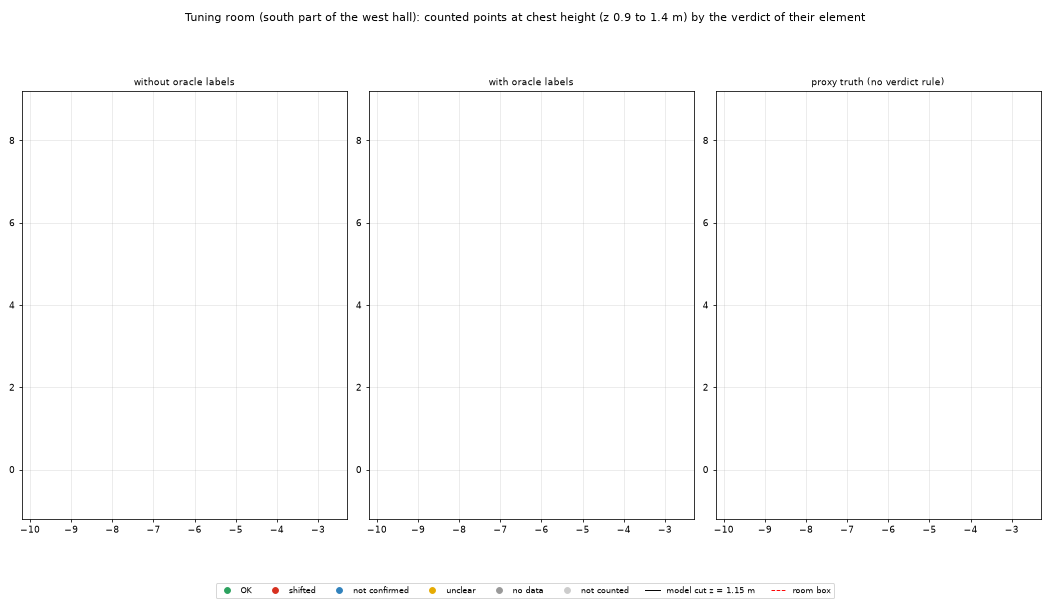

In [12]:
# Top-down view of the tuning room: counted scan points coloured by the verdict of their element (without labels, with labels) and by the proxy's truth; the model cut at chest height in black.
VERDICT_COLOUR = {"OK": "#2ca25f", "shifted": "#d7301f", "not confirmed": "#3182bd", "unclear": "#e6ab02", "no data": "#999999"}
GREY = np.array([0.80, 0.80, 0.80])
hex_rgb = lambda h: np.array([int(h[k:k + 2], 16) / 255 for k in (1, 3, 5)])


def section(els, axis, value):
    keep = [i for i in range(3) if i != axis]
    out = []
    for e in els:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        S = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t_ = s[idx, i] / (s[idx, i] - s[idx, j])
            S[idx, count[idx]] = tri[idx, i][:, keep] + t_[:, None] * (tri[idx, j][:, keep] - tri[idx, i][:, keep])
            count[idx] += 1
        out.append(S[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


rs = np.random.default_rng(SEED)
slab = np.flatnonzero((P[:, 2] >= 0.9) & (P[:, 2] <= 1.4))
pick = np.sort(rs.choice(slab, min(150_000, len(slab)), replace=False))
owner = np.full(len(P), -1)
for i, idx in enumerate(A.points_of):
    owner[idx] = i
cuts = section(elements, 2, 1.15)
fig, axs = plt.subplots(1, 3, figsize=(15, 8.6))
for ax, (title, colour_of, use) in zip(axs, (("without oracle labels", lambda i: BASE["no_labels"][i]["verdict"], use_all), ("with oracle labels", lambda i: BASE["oracle_labels"][i]["verdict"], use_oracle),
                                             ("proxy truth (no verdict rule)", lambda i: PROXY[i]["truth"], use_all))):
    element_colour = np.array([hex_rgb(VERDICT_COLOUR[colour_of(i)]) for i in range(len(elements))])
    coloured = (owner[pick] >= 0) & use[pick]
    colour = np.where(coloured[:, None], element_colour[np.maximum(owner[pick], 0)], GREY)
    order = np.argsort(coloured, kind="stable")
    ax.scatter(P[pick[order], 0], P[pick[order], 1], s=1.2, c=colour[order], linewidths=0, rasterized=True)
    ax.add_collection(LineCollection(cuts, colors="k", linewidths=0.8))
    ax.add_patch(plt.Rectangle(box_lo[:2], *(box_hi - box_lo)[:2], fill=False, ec="r", ls="--", lw=1))
    ax.set_xlim(-10.2, -2.3); ax.set_ylim(-1.2, 9.2); ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title(title, fontsize=9)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=6, color=c, label=v) for v, c in VERDICT_COLOUR.items()] + [plt.Line2D([], [], marker="o", ls="", ms=6, color=GREY, label="not counted"),
           plt.Line2D([], [], color="k", lw=1, label="model cut z = 1.15 m"), plt.Line2D([], [], color="r", ls="--", lw=1, label="room box")], loc="lower center", ncol=8, fontsize=8)
fig.suptitle("Tuning room (south part of the west hall): counted points at chest height (z 0.9 to 1.4 m) by the verdict of their element")
plt.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig(OUT / "verdicts_top_down.png", dpi=70)
plt.close(fig)
display(Image(filename=str(OUT / "verdicts_top_down.png"), width=1050))


## 10. Outputs

`proxy_truth.csv`, `diagnosis_no_labels.csv`, `patch_effect.csv`, `known_answers.csv`, `verdicts_{no_labels,oracle_labels}.csv`, `verdicts_top_down.png` in `outputs/03c/` (this room's folder, gitignored).

In [13]:
# Outputs (gitignored): the proxy, the diagnosis, the what-if, and the known answers, one CSV each
def write_csv(name, fields, rows):
    with open(OUT / name, "w", newline="") as f:
        w = csv.DictWriter(f, fields, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if isinstance(v, float) and np.isnan(v) else round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})


write_csv("proxy_truth.csv", ["global_id", "name", "ifc_class", "verdict_no_labels", "verdict_oracle_labels", "truth", "n_oracle", "n_plain", "plane_mm", "in_plane"],
          [dict(PROXY[i], global_id=e.global_id, name=META[e.global_id]["name"], ifc_class=e.ifc_class, verdict_no_labels=BASE["no_labels"][i]["verdict"], verdict_oracle_labels=BASE["oracle_labels"][i]["verdict"])
           for i, e in enumerate(elements)])
write_csv("diagnosis_no_labels.csv", ["global_id", "name", "n", "share", "fail_front", "fail_behind", "fail_element_class", "fail_clutter_class", "fail_unassigned", "fail_in_padding", "past_edge", "fail_past_edge", "fail_beyond_50mm", "share_without_past_edge",
                                      "share_without_clutter", "share_without_unassigned", "share_oracle", "share_trend_removed", "slope_u_mm_per_m", "slope_v_mm_per_m", "median_failing_mm"],
          [dict(d, global_id=elements[i].global_id, name=META[elements[i].global_id]["name"], slope_u_mm_per_m=d["slope_mm_per_m"][0], slope_v_mm_per_m=d["slope_mm_per_m"][1]) for i, d in DIAG.items()])
write_csv("patch_effect.csv", ["global_id", "name", "excluded", "truth", "verdict_off", "share_off", "points_off", "verdict_on", "share_on", "points_on", "labels_off", "labels_on"],
          [dict(global_id=e.global_id, name=META[e.global_id]["name"], excluded=EXC[i], truth=PROXY[i]["truth"], verdict_off=BASE["no_labels"][i]["verdict"], share_off=BASE["no_labels"][i]["share_within_tol"],
                points_off=BASE["no_labels"][i]["point_count"], verdict_on=BASE_P["no_labels"][i]["verdict"], share_on=BASE_P["no_labels"][i]["share_within_tol"], points_on=BASE_P["no_labels"][i]["point_count"],
                labels_off=BASE["oracle_labels"][i]["verdict"], labels_on=BASE_P["oracle_labels"][i]["verdict"]) for i, e in enumerate(elements)])
write_csv("known_answers.csv", ["run", "patch", "variant", "global_id", "name", "ifc_class", "change_mm", "expected", "actual", "right", "baseline", "pure_shift", "points", "median_mm", "median_change_mm", "share_within_tol",
                                "false_flags", "changed_untouched", "changed_names"], [dict(k, global_id=elements[k["i"]].global_id) for k in KNOWN])
print("wrote", *sorted(p.name for p in OUT.iterdir()))
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T0:.0f} s")


wrote diagnosis_no_labels.csv known_answers.csv patch_effect.csv proxy_truth.csv verdicts_no_labels.csv verdicts_oracle_labels.csv verdicts_top_down.png
peak RSS 1.64 GB, notebook run 192 s


## Answer

**Phase 2 of the tuning on room A: the own-face patch.** Thresholds fixed (`TOL` 15 mm, `MIN_FRAC_OK` 0.95). Room A shares room B's south wall `Drywall:961571` (hand-check element 6); that wall and every other element that room B's list holds (12 of 28: the floor slab and east wall that run through both rooms, two ceiling coverings, two of room B's west walls, five windows on the boundary strip) are kept in the room but **excluded from every score and from the tuning**; the list is in the slice JSON (`scoring_exclusions`) and marked in the tables. 16 elements are scored.

**Baseline (patch off).** Without labels **0 OK, 3 shifted, 25 not confirmed**; with labels 3 / 3 / 22 (all three OK with labels are excluded elements: the floor slab, the east wall and the shared wall). The label-free ICP corrects the recorded transform by 0.04 degrees and 10.3 mm. The proxy scores only **2 non-excluded elements**: the south outer wall `...919855` (clean plane at -12.6 mm, so OK by the proxy, but 61 % within 15 mm without labels and 69 % with: a plane 2.4 mm inside the line with 5 mm noise cannot pass a 95 % rule on the points, the same edge case as 03b's 1 cm move) and the shifted partition `Drywall:969917` (-118 mm, right). Six elements have no clean plane and eight have too few plain points.

**Patch, per element (section 7).** With the final patch (walls with one room-facing side, slabs, coverings, 1 cm): **no non-excluded element changes verdict**, in either variant; counts unchanged (without labels 0 / 3 / 25, with labels 3 / 3 / 22). Agreement with the proxy 1 of 2 -> 1 of 2. The south wall has no point past an edge (0 dropped). The first version (all walls) changed one element: `Drywall:964066`, a 0.7 m partition, from not confirmed to shifted at -15.9 mm (0.9 mm beyond `TOL`; 27 % of its points were past its ends; the proxy cannot judge it, 73 % in plane before the patch, 84 % after) for allowances up to 2 cm, and not at 5 cm; with `PATCH_ONE_SIDED` it is not patched and does not change.

**Known answers (section 8).** The moved wall is the south outer wall (150 mm, one-sided); no non-excluded element has proxy truth OK and a clean plane beyond tolerance to correct, so there is one move set, the door deletion and the hidden-wall deletion. Without labels: changes beyond tolerance right 4 of 5 -> 4 of 5 (the 10 cm move reads not confirmed with 2 % within, as before the patch), expected OK 0 of 1 -> 0 of 1 (the -1 cm move leaves the plane 2.6 mm from the moved face, 87 % within, not confirmed); with labels 5 of 5 and 1 of 1, unchanged. No untouched element is newly flagged, no false OK, in any of the three patch states.

**Reading.** Room A holds the patch: it changes nothing, so it neither supports nor contradicts the hall's gain. It is dominated by elements that room B also lists (12 of 28 excluded) and by walls the proxy cannot score, so most of the held-out evidence is the hall's `982078`.

**Doubts.** Two scorable elements and six runs are thin; the excluded elements would have been the informative ones (the shared wall is OK with labels, 98 %, and 78 % without: clutter, not edges).